# **Face Shape Classification & Hairstyle Recommendation**
### **Training Pipeline: HOG + SVM & Random Forest (Roboflow Dataset)**
Notebook ini dirancang khusus untuk melatih model klasifikasi bentuk wajah menggunakan dataset dari Roboflow (`faceShape.v4i.folder.zip`).
Hasil model diekspor sebagai `face_shape_svm.pkl` yang kompatibel 100% dengan backend FastAPI proyek PBL.

## **1. Hubungkan ke Google Drive & Ekstrak Dataset**
Upload file `faceShape.v4i.folder.zip` (dari `C:\Users\azure\Downloads\FaceShapeDataset\`) ke Google Drive kamu.

In [2]:
import os
import zipfile

from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

EXTRACT_DIR = '/content/dataset'
os.makedirs(EXTRACT_DIR, exist_ok=True)

# 1. File zip pertama
ZIP_PATH_1 = '/content/drive/MyDrive/faceShape/faceShape.v4i.folder.zip'
if os.path.exists(ZIP_PATH_1):
  print(f'Mengekstrak {ZIP_PATH_1}...')
  with zipfile.ZipFile(ZIP_PATH_1, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)
  print('Dataset 1 berhasil diekstrak!')
else:
  print(f'File {ZIP_PATH_1} belum ditemukan!')

# 2. File zip kedua
ZIP_PATH_2 = '/content/drive/MyDrive/faceShape/diamond face.v1i.multiclass.zip'
if os.path.exists(ZIP_PATH_2):
  print(f'Mengekstrak {ZIP_PATH_2}...')
  with zipfile.ZipFile(ZIP_PATH_2, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)
  print('Dataset 2 berhasil diekstrak!')
else:
  print(f'File {ZIP_PATH_2} belum ditemukan!')

print('Isi direktori:', os.listdir(EXTRACT_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Mengekstrak /content/drive/MyDrive/faceShape/faceShape.v4i.folder.zip...
Dataset 1 berhasil diekstrak!
Mengekstrak /content/drive/MyDrive/faceShape/diamond face.v1i.multiclass.zip...
Dataset 2 berhasil diekstrak!
Isi direktori: ['README.roboflow.txt', 'train', 'valid', 'test', 'README.dataset.txt']


## **2. Ekstraksi Fitur HOG (Histogram of Oriented Gradients)**
Spesifikasi ekstraksi disamakan dengan backend:
- Resize: 128x128 (Grayscale)
- Normalisasi intensitas piksel 0..1
- Orientasi: 9, Pixels per cell: (8,8), Cells per block: (2,2)
- Block norm: L2-Hys (Vektor: 8.100 dimensi)

In [3]:
import cv2
import numpy as np
from PIL import Image
from skimage.feature import hog
from tqdm import tqdm

# Mapping folder dataset Roboflow ke label canonical proyek
# Roboflow: heart, long, oval, round, square -> Proyek: heart, oblong, oval, round, square
FOLDER_TO_CLASS = {
    'heart': 'heart',
    'long': 'oblong',
    'oval': 'oval',
    'round': 'round',
    'square': 'square'
}

def extract_hog_features(image_path):
    try:
        img = Image.open(image_path).convert('L')
        img = img.resize((128, 128), Image.Resampling.LANCZOS)
        img_array = np.array(img, dtype=np.float32) / 255.0

        features = hog(
            img_array,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm='L2-Hys',
            transform_sqrt=True,
            feature_vector=True
        )
        return features
    except Exception as e:
        return None

# Direktori data training
TRAIN_DIR = os.path.join(EXTRACT_DIR, 'train')

# Opsi subset per kelas jika ingin ekstraksi lebih cepat (misal max 1000 gambar/kelas)
# Ubah MAX_SAMPLES_PER_CLASS = None jika ingin memakai SELURUH data (~14.000 gambar)
MAX_SAMPLES_PER_CLASS = 1000

X = []
y = []

print('Mengekstrak fitur HOG dari dataset train...')
for folder_name, canonical_class in FOLDER_TO_CLASS.items():
    class_dir = os.path.join(TRAIN_DIR, folder_name)
    if not os.path.exists(class_dir):
        print(f'Folder {class_dir} tidak ditemukan, skip.')
        continue

    all_files = [f for f in os.listdir(class_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    selected_files = all_files[:MAX_SAMPLES_PER_CLASS] if MAX_SAMPLES_PER_CLASS else all_files
    print(f'Memproses kelas {canonical_class} (dari folder {folder_name}): {len(selected_files)} gambar...')

    for fname in tqdm(selected_files):
        fpath = os.path.join(class_dir, fname)
        feat = extract_hog_features(fpath)
        if feat is not None:
            X.append(feat)
            y.append(canonical_class)

X = np.array(X)
y = np.array(y)
print(f'Ekstraksi Selesai! Total sampel: {len(X)} | Dimensi HOG: {X.shape[1]}')


Mengekstrak fitur HOG dari dataset train...
Memproses kelas heart (dari folder heart): 1000 gambar...


100%|██████████| 1000/1000 [00:13<00:00, 74.22it/s]


Memproses kelas oblong (dari folder long): 1000 gambar...


100%|██████████| 1000/1000 [00:13<00:00, 74.80it/s]


Memproses kelas oval (dari folder oval): 1000 gambar...


100%|██████████| 1000/1000 [00:13<00:00, 74.57it/s]


Memproses kelas round (dari folder round): 1000 gambar...


100%|██████████| 1000/1000 [00:13<00:00, 76.42it/s]


Memproses kelas square (dari folder square): 1000 gambar...


100%|██████████| 1000/1000 [00:13<00:00, 74.98it/s]


Ekstraksi Selesai! Total sampel: 5000 | Dimensi HOG: 8100


## **3. Split Data (Train & Test)**
Bagi data 80% pelatihan dan 20% pengujian dengan pembagian merata (*stratified*).

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f'Jumlah Data Latih: {len(X_train)}')
print(f'Jumlah Data Uji  : {len(X_test)}')


Jumlah Data Latih: 4000
Jumlah Data Uji  : 1000


## **4. Training & Evaluasi: SVM vs Random Forest**
Melatih kedua model sesuai deliverables jurnal dan PRD Notion untuk perbandingan performa.

Melatih model SVM (kernel RBF, probability=True)...
Akurasi SVM: 69.50%
Melatih model Random Forest (100 estimators)...
Akurasi Random Forest: 63.30%
=== CLASSIFICATION REPORT (SVM) ===
              precision    recall  f1-score   support

       heart       0.72      0.78      0.75       200
      oblong       0.68      0.73      0.71       200
        oval       0.66      0.64      0.65       200
       round       0.71      0.68      0.69       200
      square       0.70      0.65      0.67       200

    accuracy                           0.69      1000
   macro avg       0.69      0.70      0.69      1000
weighted avg       0.69      0.69      0.69      1000



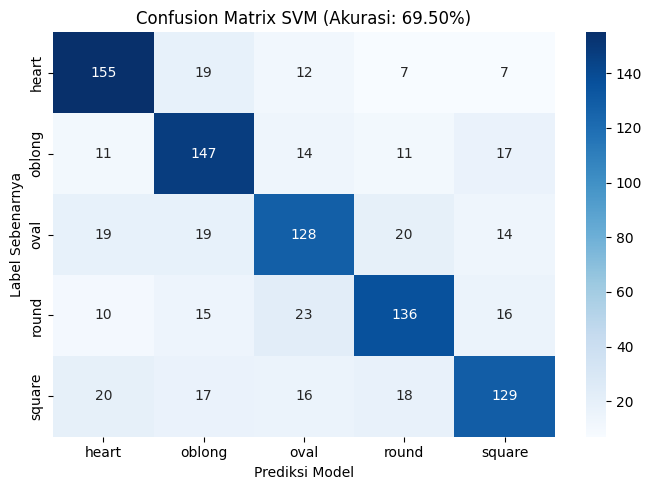

In [6]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. MODEL SUPPORT VECTOR MACHINE (SVM)
print('Melatih model SVM (kernel RBF, probability=True)...')
svm_model = SVC(kernel='rbf', C=10.0, gamma='scale', probability=True, random_state=42)
svm_model.fit(X_train, y_train)
svm_preds = svm_model.predict(X_test)
svm_acc = accuracy_score(y_test, svm_preds)
print(f'Akurasi SVM: {svm_acc * 100:.2f}%')

# 2. MODEL RANDOM FOREST
print('Melatih model Random Forest (100 estimators)...')
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)
rf_acc = accuracy_score(y_test, rf_preds)
print(f'Akurasi Random Forest: {rf_acc * 100:.2f}%')

# 3. TABEL EVALUASI SVM
print('=== CLASSIFICATION REPORT (SVM) ===')
print(classification_report(y_test, svm_preds))

# 4. VISUALISASI CONFUSION MATRIX
plt.figure(figsize=(7, 5))
cm = confusion_matrix(y_test, svm_preds, labels=svm_model.classes_)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=svm_model.classes_, yticklabels=svm_model.classes_)
plt.title(f'Confusion Matrix SVM (Akurasi: {svm_acc * 100:.2f}%)')
plt.xlabel('Prediksi Model')
plt.ylabel('Label Sebenarnya')
plt.tight_layout()
plt.show()


## **5. Export Model Artifact (`face_shape_svm.pkl`)**
Simpan model SVM terlatih dan download langsung ke komputermu.

In [7]:
import joblib
from google.colab import files

MODEL_FILE = 'face_shape_svm.pkl'
joblib.dump(svm_model, MODEL_FILE)
print(f'Model berhasil diekspor sebagai {MODEL_FILE}')

# Download otomatis
files.download(MODEL_FILE)


Model berhasil diekspor sebagai face_shape_svm.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>